#Primer ejemplo de logica de FUZZY

In [ ]:
%pip install scikit-fuzzy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 14.3 MB/s eta 0:00:00


In [ ]:
#Librerias para trabajaer
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

#Ejemplo ventilador de invernadero
# a partir de temperatura y humedad

## Entradas:

*   Temperatura: 10-45 grados centigrados (baja, confortable, alta, muy alta)
*   Humedad: 20-100% (seca, media, alta)

## Salidas:
*  Velocidad del ventilador: 0-100% (apagado, baja, media, alta, maxima)

In [ ]:
#Variables difusas de entrada
tem = ctrl.Antecedent(np.arange(10, 46,1),'temperatura')
hum = ctrl.Antecedent(np.arange(20, 101,1),'humedad')

#Variables difusas de salida
vent = ctrl.Consequent(np.arange(0, 101,1),'ventilador')

In [ ]:
#Funciones de membresia
# trapmf es por trapecio, tri por triangulo
#Temperatura
tem['baja'] = fuzz.trapmf(tem.universe,[10,10,16,21])
tem['confortable'] = fuzz.trimf(tem.universe,[18,24,29])
tem['alta'] = fuzz.trimf(tem.universe,[26,32,37])
tem['Muy_alta'] = fuzz.trapmf(tem.universe,[34,39,100,100])

# Humedad
hum['seca'] = fuzz.trapmf(hum.universe,[20,20,35,50])
hum['media'] = fuzz.trimf(hum.universe,[40,60,80])
hum['alta'] = fuzz.trapmf(hum.universe,[70,85,100,100])

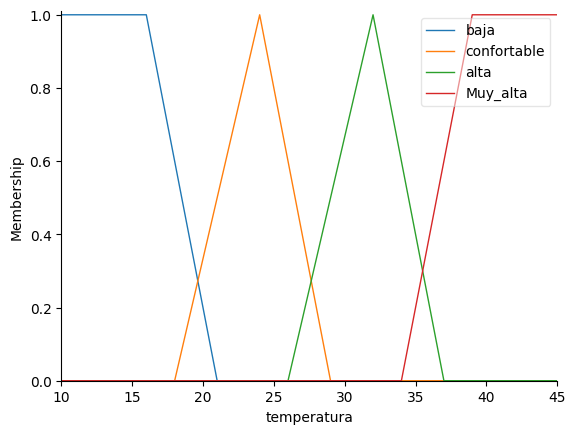

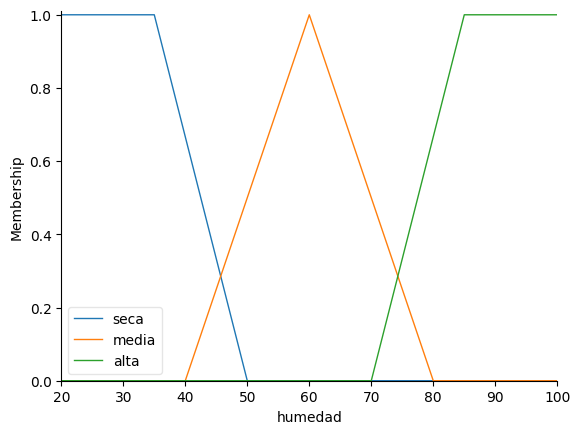

In [ ]:
#Graficar funciones de entrada
tem.view()
hum.view()
plt.show()

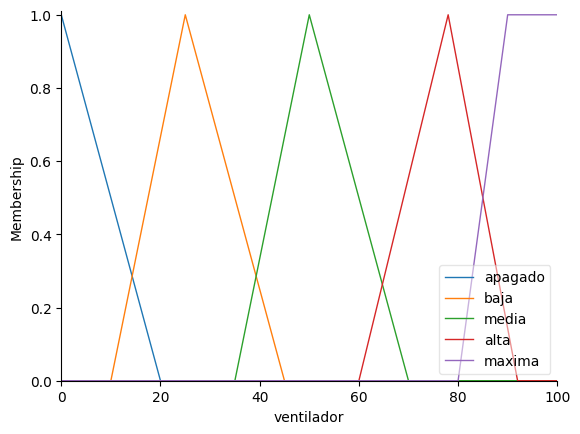

In [ ]:
#Funcion de pertenencia de la salida
vent['apagado'] = fuzz.trimf(vel.universe,[0,0,20])
vent['baja'] = fuzz.trimf(vel.universe,[10,25,45])
vent['media'] = fuzz.trimf(vel.universe,[35,50,70])
vent['alta'] = fuzz.trimf(vel.universe,[60,78,92])
vent['maxima'] = fuzz.trapmf(vel.universe,[80,90,100,100])

vent.view()
plt.show()

# Reglas linguísticas

In [ ]:
reglas_vent =[
    ctrl.Rule(tem['baja'] & hum['seca'], vent['apagado']),
    ctrl.Rule(tem['baja'] & hum['media'], vent['apagado']),
    ctrl.Rule(tem['baja'] & hum['alta'], vent['apagado']),
    ctrl.Rule(tem['confortable'] & hum['seca'], vent['baja']),
    ctrl.Rule(tem['confortable'] & hum['media'], vent['baja']),
    ctrl.Rule(tem['confortable'] & hum['alta'], vent['media']),
    ctrl.Rule(tem['alta'] & hum['seca'], vent['media']),
    ctrl.Rule(tem['alta'] & hum['media'], vent['alta']),
    ctrl.Rule(tem['alta'] & hum['alta'], vent['alta'])]

In [ ]:
#controlador
sistema_vent = ctrl.ControlSystem(reglas_vent)
simulador_vent = ctrl.ControlSystemSimulation(sistema_vent)

In [ ]:
#Declaramos una funcion para la implementacion
def recomendar_ventilacion(temperatura, humedad, mostrar=True):
  t = float(np.clip(temperatura,10,45))
  h = float(np.clip(humedad,20,100))

  simulador_vent.input['temperatura'] = t
  simulador_vent.input['humedad'] = h
  simulador_vent.compute()
  salida = simulador_vent.output['ventilador']

  if mostrar:
    print('Temperatura', t)
    print('Humedad',h)
    print('Velocidad recomendada del ventilador', salida)
  return salida


Temperatura 32.0
Humedad 82.0
Velocidad recomendada del ventilador 76.62222222222219


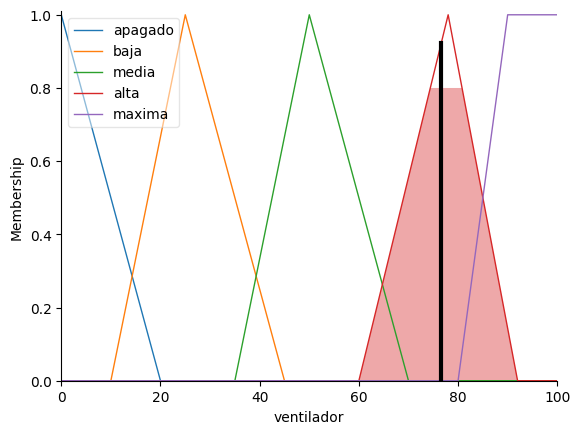

In [ ]:
def recomendar_ventilacion(temperatura, humedad, mostrar=True):
  t = float(np.clip(temperatura,10,45))
  h = float(np.clip(humedad,20,100))

  simulador_vent.input['temperatura'] = t
  simulador_vent.input['humedad'] = h
  simulador_vent.compute()
  # Usamos 'ventilador' que es como se definió en el Consequent originalmente
  salida = simulador_vent.output['ventilador']

  if mostrar:
    print('Temperatura', t)
    print('Humedad', h)
    print('Velocidad recomendada del ventilador', salida)
  return salida

# Correr primer ejemplo
velocidad = recomendar_ventilacion(32,82)
vent.view(sim=simulador_vent)
plt.show()

# Segundo ejemplo

## Recomendación para la cantidad de alimento de un comedero

Los datos de entrega por evento:
* Tiempo desde la última alimentación (horas)
* Nivel estimado del comedero(0-100%)
* Salida: Cantidad relativa a entregar(0-100% de una porcion basada en la recomendación del encargado)

In [ ]:
horas = ctrl.Antecedent(np.arange(0,12,1), 'horas_desde_comida')
nivel = ctrl.Antecedent(np.arange(0,101,1), 'nivel_actual_comedero')
porcion = ctrl.Consequent(np.arange(0,101,1), 'porcion_recomendada')

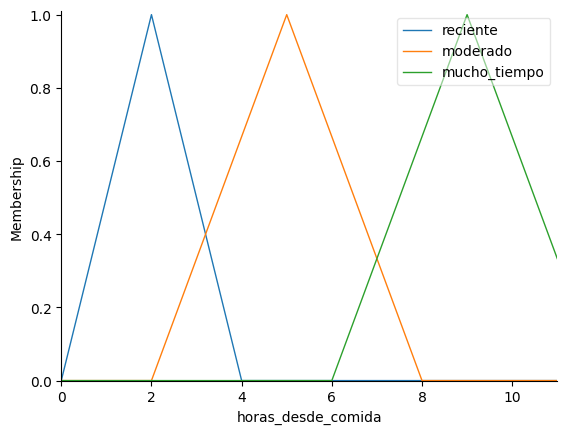

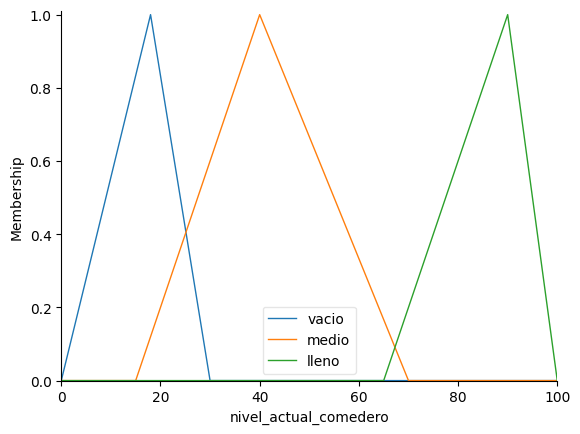

In [ ]:
#Declaramso las funciones de membrecía
horas['reciente'] = fuzz.trimf(horas.universe,[0,2,4])
horas['moderado'] = fuzz.trimf(horas.universe,[2,5,8])
horas['mucho_tiempo'] = fuzz.trimf(horas.universe,[6,9,12])

nivel['vacio'] = fuzz.trimf(nivel.universe,[0,18,30])
nivel['medio'] = fuzz.trimf(nivel.universe,[15,40,70])
nivel['lleno'] = fuzz.trimf(nivel.universe,[65,90,100])


horas.view()
nivel.view()
plt.show()

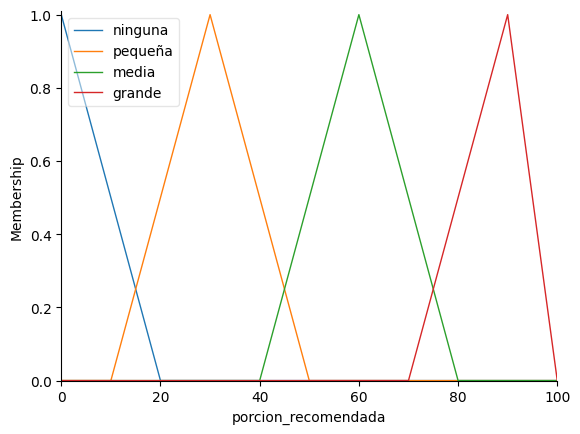

In [ ]:
#Definir salida
porcion['ninguna'] = fuzz.trimf(porcion.universe,[0,0,20])
porcion['pequeña'] = fuzz.trimf(porcion.universe,[10,30,50])
porcion['media'] = fuzz.trimf(porcion.universe,[40,60,80])
porcion['grande'] = fuzz.trimf(porcion.universe,[70,90,100])
porcion.view()
plt.show()

In [ ]:
#Reglas del comedero
reglas_comedero = [
    ctrl.Rule(horas['reciente'] & nivel['vacio'], porcion['pequeña']),
    ctrl.Rule(horas['reciente'] & nivel['medio'], porcion['ninguna']),
    ctrl.Rule(horas['moderado'] & nivel['vacio'], porcion['media']),
    ctrl.Rule(horas['moderado'] & nivel['medio'], porcion['pequeña']),
    ctrl.Rule(horas['mucho_tiempo'] & nivel['vacio'], porcion['grande']),
    ctrl.Rule(horas['mucho_tiempo'] & nivel['medio'], porcion['media']),
    ctrl.Rule(nivel['lleno'], porcion['ninguna'])]


In [ ]:
#Controlador
sistema_comedero = ctrl.ControlSystem(reglas_comedero)
simulador_comedero = ctrl.ControlSystemSimulation(sistema_comedero)

In [ ]:
#Implementacion del controlador FUZZY
def recomendar_porcion(horas_desde_comida, nivel_actual, porcion_base_kg = 1.0, mostrar=True):
  h = float(np.clip(horas_desde_comida, 0, 12))
  n = float(np.clip(nivel_actual, 0, 100)) # Corregido: usando el parámetro nivel_actual recibido
  simulador_comedero.input['horas_desde_comida'] = h
  simulador_comedero.input['nivel_actual_comedero'] = n # Corregido: clave correcta del Antecedent
  simulador_comedero.compute()

  porcion_recomendada = simulador_comedero.output['porcion_recomendada']
  porcion_kg = porcion_recomendada / 100 * porcion_base_kg

  if mostrar:
    print('Tiempo desde la ultima comida:', h)
    print('Nivel del comedero:', n)
    print(f'Porcion recomendada kg:,{porcion_kg:.2f}')
  return porcion_recomendada, porcion_kg

Tiempo desde la ultima comida: 8.0
Nivel del comedero: 10.0
Porcion recomendada kg:,1.29


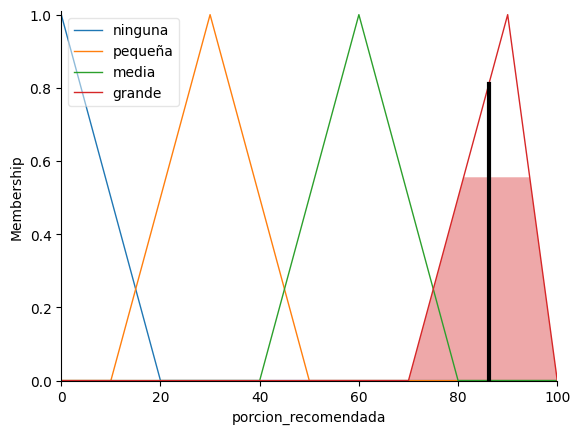

In [ ]:
#Correr el funcion del controlador
salida_relativa, salida_kg = recomendar_porcion(8,10, porcion_base_kg= 1.5)
porcion.view(sim=simulador_comedero)
plt.show()
#

